In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx

df = pd.read_csv("./data/bdc_37_fixed_broadband_served_unserved_J26_24oct2026.csv")
county_geoids_df = pd.read_csv("./data/ncstate_county_geoids.csv")

In [2]:
df = df.astype({"location_id": str,"block_geoid": str, "any_dl100_ul20": bool, "wired_dl100_ul20": bool, "terrestrial_dl100_ul20": bool})

In [3]:
df["County GEOID"] = df["block_geoid"].str[2:5]
df["Census Tract GEOID"] = df["block_geoid"].str[:11]

In [4]:
clean_df = df[["block_geoid","County GEOID", "Census Tract GEOID", "any_dl100_ul20", "wired_dl100_ul20", "terrestrial_dl100_ul20"]]

In [5]:
clean_df.head()

,block_geoid,County GEOID,Census Tract GEOID,any_dl100_ul20,wired_dl100_ul20,terrestrial_dl100_ul20
0,371719303011000,171,37171930301,True,False,True
1,371899208002015,189,37189920800,True,True,True
2,371899209003025,189,37189920900,True,True,True
3,371899207022041,189,37189920702,True,True,True
4,371899202001018,189,37189920200,True,True,True


In [6]:
county_geoids_df = county_geoids_df.astype({"FIPS Code": str})
county_geoids_df["FIPS Code"] = county_geoids_df["FIPS Code"].str[2:]
county_geoids_df["County"] = county_geoids_df["County"].str.replace(" County", "").str.strip()
county_geoids_df = county_geoids_df.drop(columns="Tracts")
county_geoids_df.head()

,County,FIPS Code
0,Alamance,001
1,Alexander,003
2,Alleghany,005
3,Anson,007
4,Ashe,009


In [7]:
merged_df = pd.merge(clean_df, county_geoids_df[["County", "FIPS Code"]], left_on="County GEOID", right_on="FIPS Code", how="left")
county_col = merged_df.pop("County")
merged_df = merged_df.drop(columns=["FIPS Code"])
merged_df.insert(1, "County", county_col)
merged_df.head()

,block_geoid,County,County GEOID,Census Tract GEOID,any_dl100_ul20,wired_dl100_ul20,terrestrial_dl100_ul20
0,371719303011000,Surry,171,37171930301,True,False,True
1,371899208002015,Watauga,189,37189920800,True,True,True
2,371899209003025,Watauga,189,37189920900,True,True,True
3,371899207022041,Watauga,189,37189920702,True,True,True
4,371899202001018,Watauga,189,37189920200,True,True,True


In [44]:
merged_df["has_terra_service"] = merged_df["terrestrial_dl100_ul20"] == True

threshold = 90

In [45]:
by_county = merged_df.groupby("County")["has_terra_service"].agg(["size","sum","mean"])
by_county = by_county.sort_values(by="mean", ascending=False)
by_county["% With Coverage"] = round(by_county["mean"] * 100,2)
by_county = by_county.rename(columns={"size": "Total Locations", "sum": "Has Terrestrial Service"})
by_county = by_county[by_county["Total Locations"] >= 100]
by_county = by_county[by_county["% With Coverage"] >= threshold]
by_county = by_county.drop(columns="mean")
by_county.head()

,Total Locations,Has Terrestrial Service,% With Coverage
County,,,
Mecklenburg,343110,342799,99.91
Yadkin,18790,18767,99.88
New Hanover,91798,91648,99.84
Brunswick,106119,105926,99.82
Davie,20358,20319,99.81


In [46]:
by_tract = merged_df.groupby(["County", "Census Tract GEOID"], as_index=False)["has_terra_service"].agg(["size","sum","mean"])
by_tract = by_tract.sort_values(by="mean", ascending=False)
by_tract["% With Coverage"] = round(by_tract["mean"] * 100,2)
by_tract = by_tract.rename(columns={"size": "Total Locations", "sum": "Has Terrestrial Service"})
by_tract = by_tract.drop(columns="mean")
by_tract = by_tract[by_tract["Total Locations"] >= 100]
by_tract = by_tract[by_tract["% With Coverage"] >= threshold]
print(len(by_tract))
by_tract.head()

2375


,County,Census Tract GEOID,Total Locations,Has Terrestrial Service,% With Coverage
7,Alamance,37001020601,1457,1457,100.0
2647,Yadkin,37197050503,1577,1577,100.0
0,Alamance,37001020100,1694,1694,100.0
1,Alamance,37001020200,1639,1639,100.0
2,Alamance,37001020301,1340,1340,100.0


In [47]:
by_county.to_excel(f"./results/available/PercentWithCoveragebyCountywithThreshold{threshold}.xlsx", index=True)
by_tract.to_excel(f"./results/available/PercentWithCoveragebyTractwithThreshold{threshold}.xlsx", index=True)

Everything past this cell I relied on assistance from Claude to do. Everything was still handwritten I just had Claude walking me through these things while trying to help me understand it.

In [48]:
shape_df = gpd.read_file("data/tl_2020_37_tract.zip").to_crs(32119)
shape_df.head()

,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,37,141,920300,37141920300,9203,Census Tract 9203,G5020,S,236115472,605423,+34.6713171,-078.0020072,"POLYGON ((686896.998 103394.168, 687069.83 103..."
1,37,141,990100,37141990100,9901,Census Tract 9901,G5020,S,0,133298393,+34.3492469,-077.6031267,"POLYGON ((727968.698 60800.547, 727993.265 608..."
2,37,071,031600,37071031600,316,Census Tract 316,G5020,S,22744042,66304,+35.2681382,-081.2849294,"POLYGON ((398030.831 170385.243, 398034.506 17..."
3,37,071,031800,37071031800,318,Census Tract 318,G5020,S,6071060,8149,+35.2623339,-081.2292201,"POLYGON ((404259.886 170518.838, 404382.904 17..."
4,37,155,961801,37155961801,9618.01,Census Tract 9618.01,G5020,S,103973789,0,+34.6244596,-079.2476138,"POLYGON ((581155.624 94311.87, 581164.57 94327..."


In [49]:
map = pd.merge(shape_df, by_tract, left_on="GEOID", right_on="Census Tract GEOID", how="left")
map.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 2672 entries, 0 to 2671
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   STATEFP                  2672 non-null   str     
 1   COUNTYFP                 2672 non-null   str     
 2   TRACTCE                  2672 non-null   str     
 3   GEOID                    2672 non-null   str     
 4   NAME                     2672 non-null   str     
 5   NAMELSAD                 2672 non-null   str     
 6   MTFCC                    2672 non-null   str     
 7   FUNCSTAT                 2672 non-null   str     
 8   ALAND                    2672 non-null   int64   
 9   AWATER                   2672 non-null   int64   
 10  INTPTLAT                 2672 non-null   str     
 11  INTPTLON                 2672 non-null   str     
 12  geometry                 2672 non-null   geometry
 13  County                   2375 non-null   str     
 14  

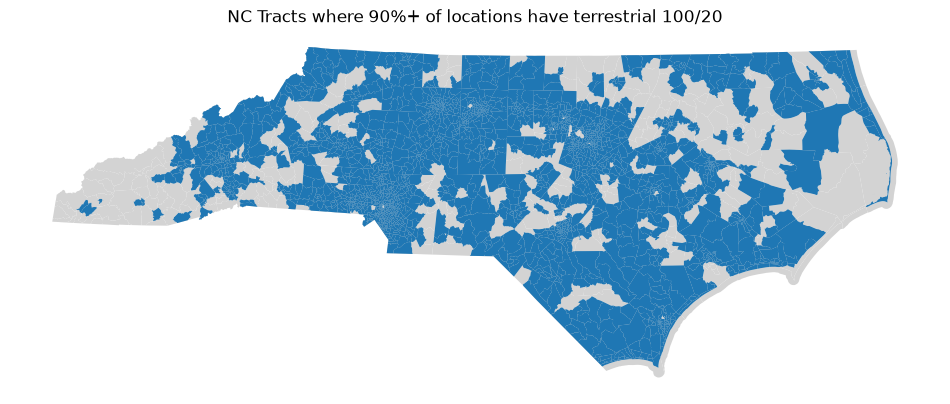

In [50]:
fig, ax = plt.subplots(figsize=(12,6))
map.plot(ax=ax, color="lightgray")

flagged = map[map["% With Coverage"].notna()]
flagged.plot(ax=ax, color="tab:blue")

ax.set_axis_off()
ax.set_title(f"NC Tracts where {threshold}%+ of locations have terrestrial 100/20")

fig.savefig(f"results/available/flagged_tracts_{threshold}pct.png", dpi=150, bbox_inches="tight")

In [51]:
flagged_cleaned = flagged[["GEOID", "geometry"]]
flagged_cleaned = flagged_cleaned.reset_index(drop=True)

flagged_pairs = gpd.sjoin(flagged_cleaned, flagged_cleaned, predicate="touches")

In [52]:
graph = nx.Graph()

pairs = zip(flagged_pairs["GEOID_left"], flagged_pairs["GEOID_right"])

graph.add_nodes_from(flagged_cleaned["GEOID"])
graph.add_edges_from(pairs)

groups = nx.connected_components(graph)

cluster = {}
for index, group in enumerate(groups, start=1):
    for geoid in group:
        cluster[geoid] = index

flagged["Cluster"] = flagged["GEOID"].map(cluster)

flagged.head()
flagged.to_excel(f"./results/available/FlaggedTractswith{threshold}.xlsx", index=True)

C:\Users\lssen\AppData\Local\Temp\ipykernel_23932\1522031310.py:18: UserWarning: Cell contents too long, truncated to 32767 characters
  flagged.to_excel(f"./results/available/FlaggedTractswith{threshold}.xlsx", index=True)


In [53]:
flagged_clusters = flagged.groupby(["Cluster"], as_index=False).agg({"Total Locations": "sum", "Has Terrestrial Service": "sum","Census Tract GEOID": "count", "County": lambda x: list(x.unique())})
flagged_clusters["% With Coverage"] = round((flagged_clusters["Has Terrestrial Service"] / flagged_clusters["Total Locations"]) * 100, 2)
flagged_clusters = flagged_clusters.sort_values(["Has Terrestrial Service"], ascending=False)
flagged_clusters = flagged_clusters.rename(columns={"Census Tract GEOID": "# of Tracts"})
flagged_clusters.head()

,Cluster,Total Locations,Has Terrestrial Service,# of Tracts,County,% With Coverage
0,1,3782151.0,3729632.0,2274,"[Pender, Gaston, Robeson, Sampson, Cleveland, ...",98.61
1,2,141588.0,137444.0,71,"[Dare, Bertie, Northampton, Gates, Chowan, War...",97.07
2,3,10215.0,9953.0,8,[Vance],97.44
10,11,7264.0,6903.0,4,[Granville],95.03
6,7,4607.0,4468.0,3,[Macon],96.98


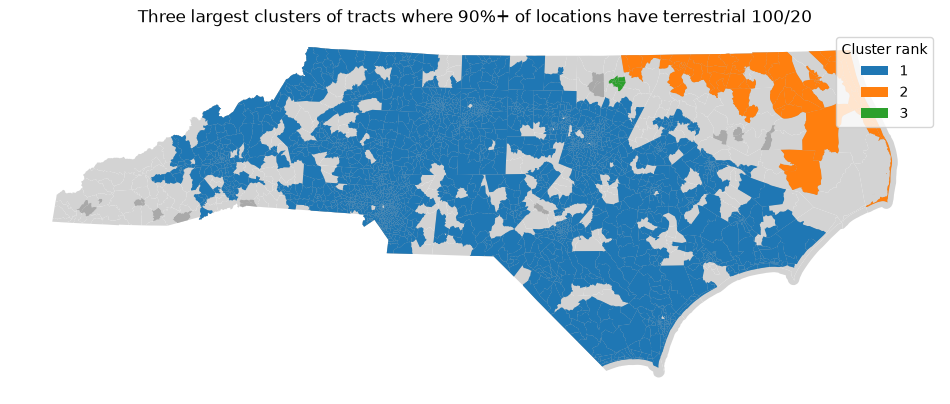

In [54]:
flagged_clusters["Rank"] = range(1, len(flagged_clusters) + 1)
rank_of = dict(zip(flagged_clusters["Cluster"], flagged_clusters["Rank"]))
flagged["Rank"] = flagged["Cluster"].map(rank_of)

fig, ax = plt.subplots(figsize=(12,6))
map.plot(ax=ax, color="lightgray")
flagged.plot(ax=ax, color="darkgray")
top3 = flagged[flagged["Rank"] <= 3]
top3.plot(ax=ax, column="Rank", categorical=True, legend=True, legend_kwds={"title": "Cluster rank"})

ax.set_axis_off()
ax.set_title(f"Three largest clusters of tracts where {threshold}%+ of locations have terrestrial 100/20")
fig.savefig(f"results/available/top3_clusters_{threshold}pct.png", dpi=150, bbox_inches="tight")